# Лабораторная работа №3
## Дискретные системы

**Вариант: 5**

Работа выполнена в среде Python (NumPy / SciPy / Matplotlib).
Каждая функция, строящая график, дополнительно **сохраняет его в папку
проекта** `figures/`.

In [1]:
import numpy as np
import os
import matplotlib.pyplot as plt
import matplotlib
from scipy import signal as sps

rng = np.random.default_rng()
plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.grid"] = True

FIG_DIR = os.path.expanduser("~/University/TnAofDSP/lab3/source")
import os
os.makedirs(FIG_DIR, exist_ok=True)

def save_and_show(fig=None, name="figure"):
    '''Отображает график и сохраняет его как PNG
    в папку проекта figures/. Используется всеми построениями в работе.'''
    if fig is None:
        fig = plt.gcf()
    path = os.path.join(FIG_DIR, f"{name}.png")
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"[график сохранён: {path}]")

In [2]:
def create_signal(SIGNAL_BEGIN, SIGNAL_END):
    assert SIGNAL_END < SIGNAL_BEGIN, "SIGNAL END MUST BE BIGGER THAN BEGIN"
        
    n = np.arange(SIGNAL_BEGIN, SIGNAL_END + 1)
    x = rng.random(SIGNAL_END - SIGNAL_BEGIN + 1)
    
    return n, x

def signal_mul(MULT_COEF, SIGNAL):
    
    return SIGNAL * MULT_COEF

def signal_sum(FIRST_SIGNAL, SECOND_SIGNAL):
    if len(FIRST_SIGNAL) >= len(SECOND_SIGNAL):
        long_sig, short_sig = FIRST_SIGNAL, SECOND_SIGNAL
    else:
        long_sig, short_sig = SECOND_SIGNAL, FIRST_SIGNAL
    
    result = long_sig
    
    for i in range(len(short_sig)):
        result[i] += short_sig[i]
        
    return result

def delay(SIGNAL, BACKWARD_STEP):
    if BACKWARD_STEP >= len(SIGNAL):
        return np.zeros(len(SIGNAL))
        
    if BACKWARD_STEP <= 0:
        return SIGNAL.copy()
        
    new_signal = np.zeros(len(SIGNAL))
    new_signal[BACKWARD_STEP:] = SIGNAL[:-BACKWARD_STEP]
    return new_signal

def get_AFC(SIGNAL, num_points: int = 512):
    n = np.arange(len(SIGNAL))
    exponent = np.exp(-1j * np.outer(np.linspace(0, np.pi, num_points), n))
    return np.abs(np.dot(exponent, SIGNAL))

---
# Часть 1. Общая

Возьмите систему $y(n) = 0,3 x(n) + 0,6 x(n − 1) + 0,3 x(n − 2) − 0,9 y(n − 2)$ и 

**а)** реализуйте её циклом с явным моделированием памяти по схеме.

In [3]:
class IIRfilter: 
    def __init__(self, b, a):

        self.b = np.array(b, dtype=float)
        self.a = np.array(a, dtype=float)
        
        self.A = len(b) - 1
        self.B = len(a) - 1 
        
        self.mem_x = np.zeros(self.A)
        self.mem_y = np.zeros(self.B)

    def process_sample(self, x): # Обрабатываем отдельный сэмпл
        y = self.b[0] * x
        
        if self.A > 0:
            y += np.dot(self.b[1:], self.mem_x)
            self.mem_x = np.roll(self.mem_x, 1)
            self.mem_x[0] = x
            
        if self.B > 0:
            y -= np.dot(self.a[1:], self.mem_y)
            self.mem_y = np.roll(self.mem_y, 1)
            self.mem_y[0] = y
            
        return y

    def process_signal(self, X): # Обрабатываем весь сигнал
        return np.array([self.process_sample(x) for x in X])

    def reset_memory(self):
        self.mem_x.fill(0)
        self.mem_y.fill(0)

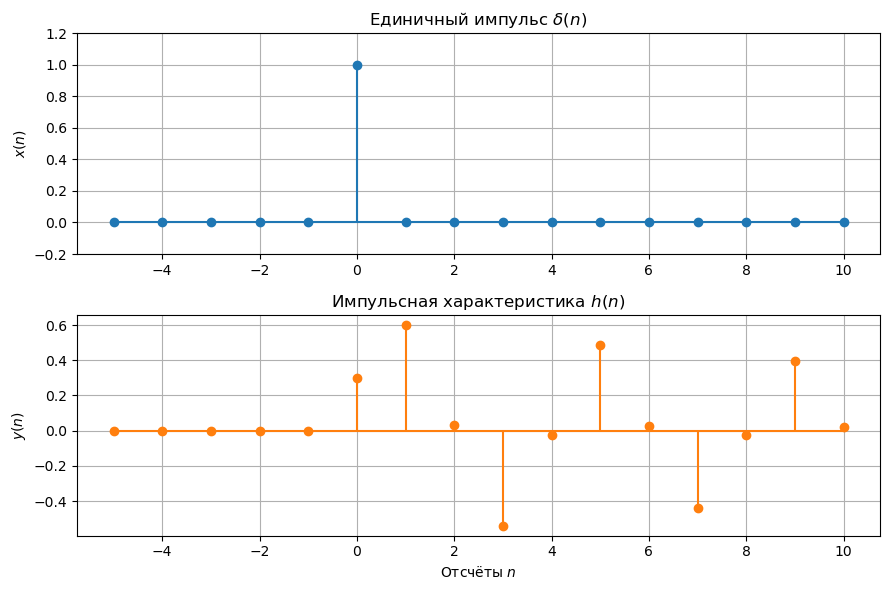

[график сохранён: /home/stanislau/University/TnAofDSP/lab3/source/1_1_filter.png]


In [4]:
N = np.arange(16) - 5
X = np.zeros(len(N), dtype=float)
X[5] = 1.0

b = [0.3, 0.6, 0.3] # Входные данные
a = [1.0, 0.0, 0.9] # Выходные данные

flt = IIRfilter(b, a) # Используем свой фильтр с явным моделированием памяти
Y1 = flt.process_signal(X)

fig, (Xgraph, Ygraph) = plt.subplots(2, 1, figsize=(9, 6))

Xgraph.stem(N, X, basefmt="C0-")
Xgraph.set_ylabel("$x(n)$")
Xgraph.set_title("Единичный импульс $\delta(n)$")
Xgraph.set_ylim(-0.2, 1.2)

Ygraph.stem(N, Y1, basefmt="C1-", linefmt="C1-", markerfmt="C1o")
Ygraph.set_xlabel("Отсчёты $n$")
Ygraph.set_ylabel("$y(n)$")
Ygraph.set_title("Импульсная характеристика $h(n)$")

plt.tight_layout()
save_and_show(fig, name="1_1_filter")

**б)** реализуйте её используя ``filter(b, a, x)`` (в Python это ``sps.lfilter``)

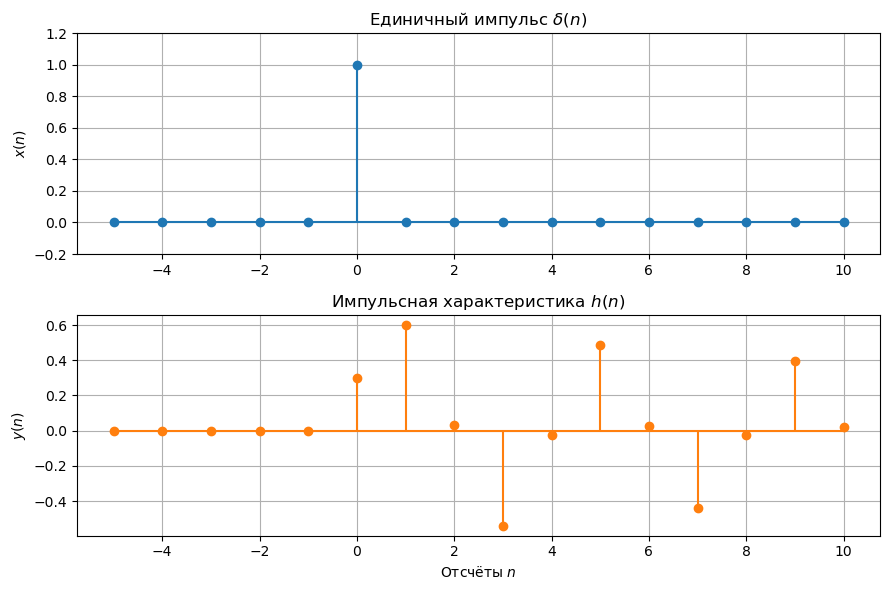

[график сохранён: /home/stanislau/University/TnAofDSP/lab3/source/1_2_filter.png]


In [5]:
N = np.arange(16) - 5
X = np.zeros(len(N), dtype=float)
X[5] = 1.0

b = [0.3, 0.6, 0.3] # Входные данные
a = [1.0, 0.0, 0.9] # Выходные данные

Y2 = sps.lfilter(b,a,X)

fig, (Xgraph, Ygraph) = plt.subplots(2, 1, figsize=(9, 6))

Xgraph.stem(N, X, basefmt="C0-")
Xgraph.set_ylabel("$x(n)$")
Xgraph.set_title("Единичный импульс $\delta(n)$")
Xgraph.set_ylim(-0.2, 1.2)

Ygraph.stem(N, Y2, basefmt="C1-", linefmt="C1-", markerfmt="C1o")
Ygraph.set_xlabel("Отсчёты $n$")
Ygraph.set_ylabel("$y(n)$")
Ygraph.set_title("Импульсная характеристика $h(n)$")

plt.tight_layout()
save_and_show(fig, name="1_2_filter")

**в)** Подайте на обе реализации дельта-импульс и проверьте совпадение: ``max(abs(y1 ‐ y2))`` должно быть меньше $1e‐12$.

In [6]:
assert np.max(abs(Y1 - Y2)) < 1e-12, "False answer"
print("Выходные значения с нашего фильтра", Y1)
print("Выходные значения с scipy функции", Y2)
print("Максимальная разность по модулю", np.max(abs(Y1 - Y2)))

Выходные значения с нашего фильтра [ 0.        0.        0.        0.        0.        0.3       0.6
  0.03     -0.54     -0.027     0.486     0.0243   -0.4374   -0.02187
  0.39366   0.019683]
Выходные значения с scipy функции [ 0.        0.        0.        0.        0.        0.3       0.6
  0.03     -0.54     -0.027     0.486     0.0243   -0.4374   -0.02187
  0.39366   0.019683]
Максимальная разность по модулю 0.0


**г)** По полученной импульсной характеристике вычислите АЧХ прямым суммированием и сравните с результатом ``freqz(b, a, 512)``. Удвойте длину h(n) и убедитесь, что график перестал меняться

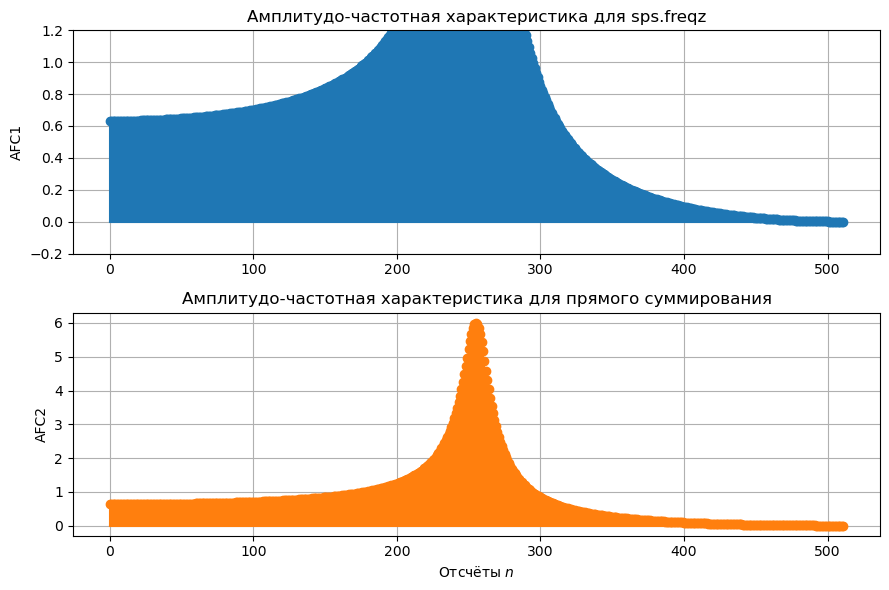

[график сохранён: /home/stanislau/University/TnAofDSP/lab3/source/1_4_AFC.png]


In [20]:
N = np.arange(1024)
X = np.zeros(len(N), dtype=float)
X[0] = 1.0

Y2 = sps.lfilter(b,a,X)

_, AFC1 = np.abs(sps.freqz(b, a, worN = 512))
AFC2 = get_AFC(Y2)

fig, (AFC1graph, AFC2graph) = plt.subplots(2, 1, figsize=(9, 6))

AFC1graph.stem(np.arange(len(AFC1)), AFC1, basefmt="C0-")
AFC1graph.set_ylabel("AFC1")
AFC1graph.set_title("Амплитудо-частотная характеристика для sps.freqz")
AFC1graph.set_ylim(-0.2, 1.2)

AFC2graph.stem(np.arange(len(AFC2)), AFC2, basefmt="C1-", linefmt="C1-", markerfmt="C1o")
AFC2graph.set_xlabel("Отсчёты $n$")
AFC2graph.set_ylabel("AFC2")
AFC2graph.set_title("Амплитудо-частотная характеристика для прямого суммирования")

plt.tight_layout()
save_and_show(fig, name="1_4_AFC")